In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:

# 1. IMPORT LIBRARIES AND LOAD DATA


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Google Colab: upload both CSV files
from google.colab import files

uploaded = files.upload()

train_df = pd.read_csv("dataset_C_training.csv")
test_df = pd.read_csv("dataset_C_testing.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Saving dataset_C_testing.csv to dataset_C_testing (3).csv
Saving dataset_C_training.csv to dataset_C_training (3).csv
Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


In [7]:
import pandas as pd

train = pd.read_csv('/content/dataset_C_training.csv')

test = pd.read_csv('/content/dataset_C_testing.csv')

print("Training dataset loaded:", train.shape)
print("Testing dataset loaded:", test.shape)

Training dataset loaded: (4756, 31)
Testing dataset loaded: (4749, 30)


In [8]:
print("TRAINING INFORMATION")

train.info()

print("\nTESTING INFORMATION")

test.info()

print("\nTraining Missing Values")

print(train.isnull().sum().sort_values(ascending=False))

print("\nTarget Distribution")

print(train['covid_vaccine'].value_counts())

TRAINING INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance           

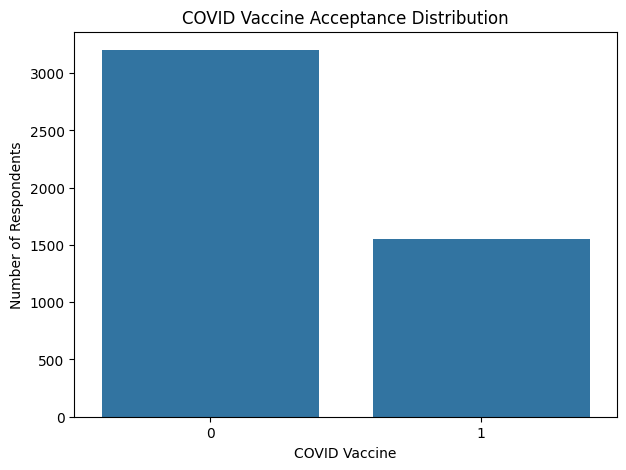

In [10]:
#Target variable visualisation

plt.figure(figsize=(7,5))

sns.countplot(
    data=train,
    x='covid_vaccine'
)

plt.title('COVID Vaccine Acceptance Distribution')
plt.xlabel('COVID Vaccine')
plt.ylabel('Number of Respondents')

plt.show()

covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


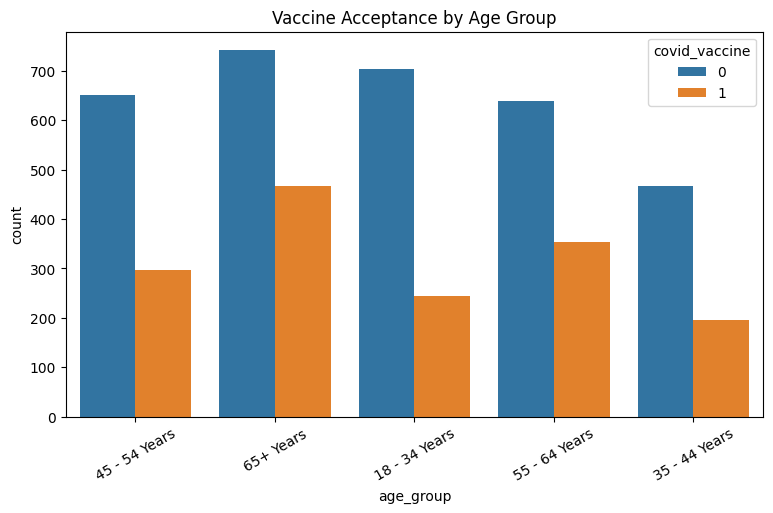

In [11]:
#Exploratory Data Analysis
# Target distribution percentage

print(
    train['covid_vaccine']
    .value_counts(normalize=True) * 100
)

# Age group distribution

plt.figure(figsize=(9,5))

sns.countplot(
    data=train,
    x='age_group',
    hue='covid_vaccine'
)

plt.title('Vaccine Acceptance by Age Group')
plt.xticks(rotation=30)

plt.show()

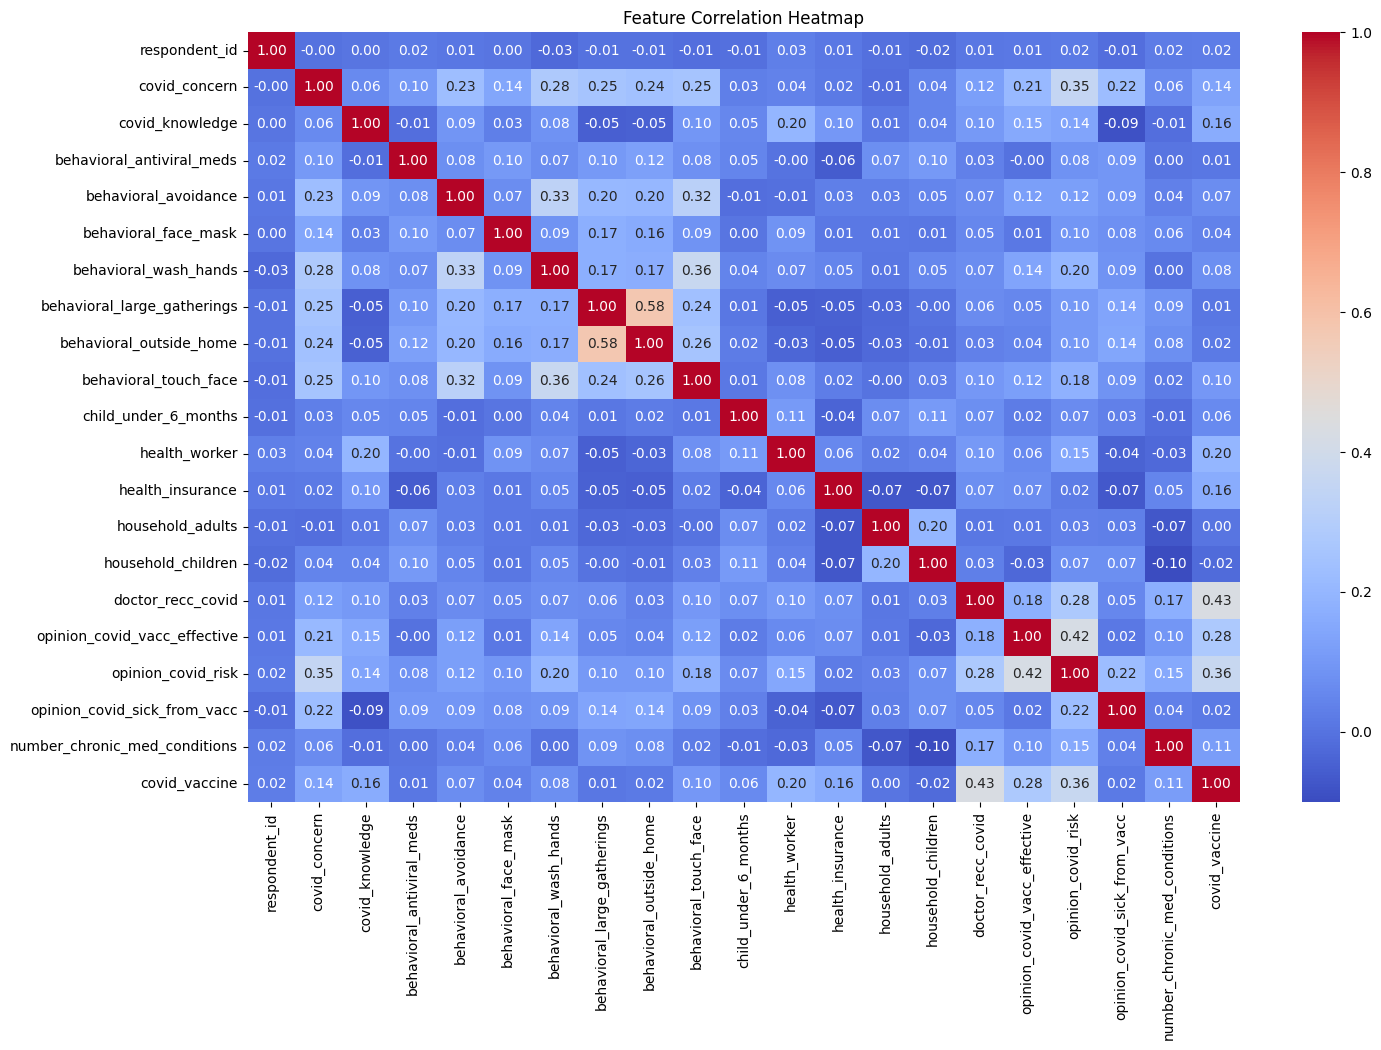

In [12]:
#Correlation analysis
numeric_data = train.select_dtypes(
    include=['int64', 'float64']
)

plt.figure(figsize=(16,10))

sns.heatmap(
    numeric_data.corr(),
    cmap='coolwarm',
    annot=True,
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')

plt.show()

In [13]:
#Prepare features and target
TARGET = 'covid_vaccine'

# Separate target
X = train.drop(
    columns=['respondent_id', TARGET]
)

y = train[TARGET]

# Testing features
X_test = test.drop(
    columns=['respondent_id']
)

# Save test IDs
test_ids = test['respondent_id']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Test shape:", X_test.shape)

X shape: (4756, 29)
y shape: (4756,)
Test shape: (4749, 29)


In [14]:
#Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Categorical Features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [15]:
#Preprocessing
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [16]:
#Train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Validation records:", X_val.shape)

Training records: (3804, 29)
Validation records: (952, 29)


In [17]:
#Build machine-learning models separately
results = []
trained_models = {}

def evaluate_model(name, model):

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    accuracy = accuracy_score(y_val, predictions)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )

    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    auc = roc_auc_score(y_val, probabilities)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': auc
    })

    trained_models[name] = model

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC AUC:", round(auc, 4))

    print("\nClassification Report:")
    print(classification_report(y_val, predictions))

    return model

In [18]:
#Logistic Regression
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

evaluate_model(
    'Logistic Regression',
    logistic_model
)


Model: Logistic Regression
Accuracy: 0.77
Precision: 0.6243
Recall: 0.7428
F1 Score: 0.6784
ROC AUC: 0.8282

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       641
           1       0.62      0.74      0.68       311

    accuracy                           0.77       952
   macro avg       0.74      0.76      0.75       952
weighted avg       0.78      0.77      0.77       952



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['covid_concern',
                                                   'covid_knowledge',
                                                   'behavioral_antiviral_meds',
                                                   'behavioral_avoidance',
                                                   'behavioral_face_mask',
                                                   'behavioral_wash_hands',
                                                   'behavioral_large_gatherings',
                                                   'behavioral_outside_home'...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['age_group', 'education',
                                                   'race', 'sex',
                                                   'income_poverty',
                                                   'marital_status',
                                                   'rent_or_own',
                                                   'employment_status',
                                                   'census_msa',
                                                   'employment_sector'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [19]:
#Random Forest
random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

evaluate_model(
    'Random Forest',
    random_forest_model
)


Model: Random Forest
Accuracy: 0.7931
Precision: 0.6993
Recall: 0.6431
F1 Score: 0.67
ROC AUC: 0.8304

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       641
           1       0.70      0.64      0.67       311

    accuracy                           0.79       952
   macro avg       0.77      0.75      0.76       952
weighted avg       0.79      0.79      0.79       952



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['covid_concern',
                                                   'covid_knowledge',
                                                   'behavioral_antiviral_meds',
                                                   'behavioral_avoidance',
                                                   'behavioral_face_mask',
                                                   'behavioral_wash_hands',
                                                   'behavioral_large_gatherings',
                                                   'behavioral_outside_home'...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['age_group', 'education',
                                                   'race', 'sex',
                                                   'income_poverty',
                                                   'marital_status',
                                                   'rent_or_own',
                                                   'employment_status',
                                                   'census_msa',
                                                   'employment_sector'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=12,
                                        min_samples_leaf=2, min_samples_split=5,
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [20]:
#Extra Trees Classifier
extra_trees_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', ExtraTreesClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

evaluate_model(
    'Extra Trees',
    extra_trees_model
)


Model: Extra Trees
Accuracy: 0.7868
Precision: 0.68
Recall: 0.6559
F1 Score: 0.6678
ROC AUC: 0.8284

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.85      0.84       641
           1       0.68      0.66      0.67       311

    accuracy                           0.79       952
   macro avg       0.76      0.75      0.76       952
weighted avg       0.78      0.79      0.79       952



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['covid_concern',
                                                   'covid_knowledge',
                                                   'behavioral_antiviral_meds',
                                                   'behavioral_avoidance',
                                                   'behavioral_face_mask',
                                                   'behavioral_wash_hands',
                                                   'behavioral_large_gatherings',
                                                   'behavioral_outside_home'...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['age_group', 'education',
                                                   'race', 'sex',
                                                   'income_poverty',
                                                   'marital_status',
                                                   'rent_or_own',
                                                   'employment_status',
                                                   'census_msa',
                                                   'employment_sector'])])),
                ('classifier',
                 ExtraTreesClassifier(class_weight='balanced', max_depth=12,
                                      min_samples_leaf=2, min_samples_split=5,
                                      n_estimators=300, n_jobs=-1,
                                      random_state=42))])

In [23]:
#Gradient Boosting
gradient_boosting_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.8,
            random_state=42
        ))
    ]
)

evaluate_model(
    'Gradient Boosting',
    gradient_boosting_model
)


Model: Gradient Boosting
Accuracy: 0.7962
Precision: 0.7368
Recall: 0.5852
F1 Score: 0.6523
ROC AUC: 0.833

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       641
           1       0.74      0.59      0.65       311

    accuracy                           0.80       952
   macro avg       0.78      0.74      0.75       952
weighted avg       0.79      0.80      0.79       952



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['covid_concern',
                                                   'covid_knowledge',
                                                   'behavioral_antiviral_meds',
                                                   'behavioral_avoidance',
                                                   'behavioral_face_mask',
                                                   'behavioral_wash_hands',
                                                   'behavioral_large_gatherings',
                                                   'behavioral_outside_home'...
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['age_group', 'education',
                                                   'race', 'sex',
                                                   'income_poverty',
                                                   'marital_status',
                                                   'rent_or_own',
                                                   'employment_status',
                                                   'census_msa',
                                                   'employment_sector'])])),
                ('classifier',
                 GradientBoostingClassifier(learning_rate=0.05,
                                            n_estimators=150, random_state=42,
                                            subsample=0.8))])

In [27]:
#AdaBoost
adaboost_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('classifier', AdaBoostClassifier(
            n_estimators=150,
            learning_rate=0.5,
            random_state=42
        ))
    ]
)

evaluate_model(
    'AdaBoost',
    adaboost_model
)


Model: AdaBoost
Accuracy: 0.7941
Precision: 0.7578
Recall: 0.5434
F1 Score: 0.633
ROC AUC: 0.8298

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.92      0.86       641
           1       0.76      0.54      0.63       311

    accuracy                           0.79       952
   macro avg       0.78      0.73      0.74       952
weighted avg       0.79      0.79      0.78       952



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['covid_concern',
                                                   'covid_knowledge',
                                                   'behavioral_antiviral_meds',
                                                   'behavioral_avoidance',
                                                   'behavioral_face_mask',
                                                   'behavioral_wash_hands',
                                                   'behavioral_large_gatherings',
                                                   'behavioral_outside_home'...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['age_group', 'education',
                                                   'race', 'sex',
                                                   'income_poverty',
                                                   'marital_status',
                                                   'rent_or_own',
                                                   'employment_status',
                                                   'census_msa',
                                                   'employment_sector'])])),
                ('classifier',
                 AdaBoostClassifier(learning_rate=0.5, n_estimators=150,
                                    random_state=42))])

In [28]:
#Model performance comparison
#Compare all five models
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'ROC AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
3,Gradient Boosting,0.7962,0.7368,0.5852,0.6523,0.8330
1,Random Forest,0.7931,0.6993,0.6431,0.6700,0.8304
4,AdaBoost,0.7941,0.7578,0.5434,0.6330,0.8298
2,Extra Trees,0.7868,0.6800,0.6559,0.6678,0.8284
0,Logistic Regression,0.7700,0.6243,0.7428,0.6784,0.8282


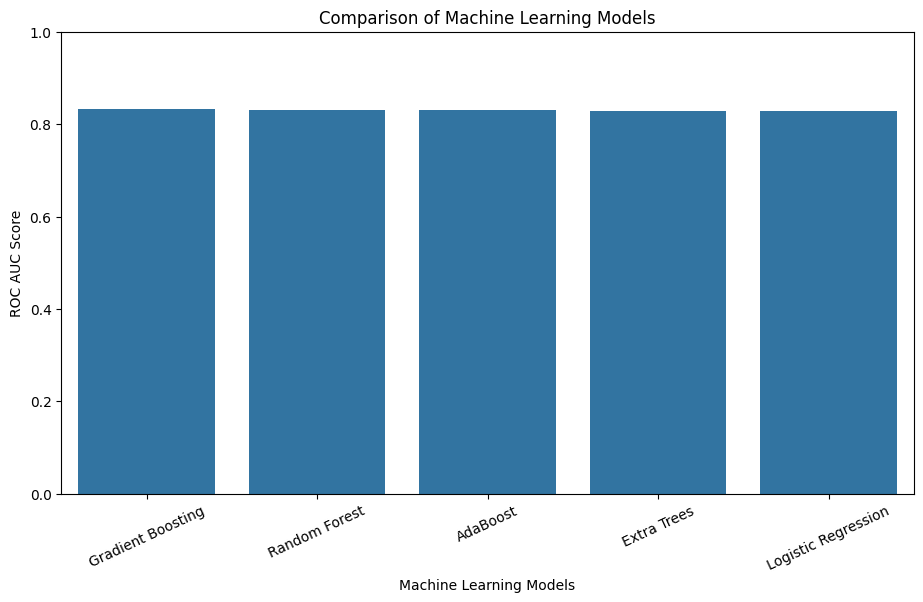

In [29]:
#Model performance graph
plt.figure(figsize=(11,6))

sns.barplot(
    data=results_df,
    x='Model',
    y='ROC AUC'
)

plt.title('Comparison of Machine Learning Models')
plt.ylabel('ROC AUC Score')
plt.xlabel('Machine Learning Models')

plt.xticks(rotation=25)
plt.ylim(0, 1)

plt.show()

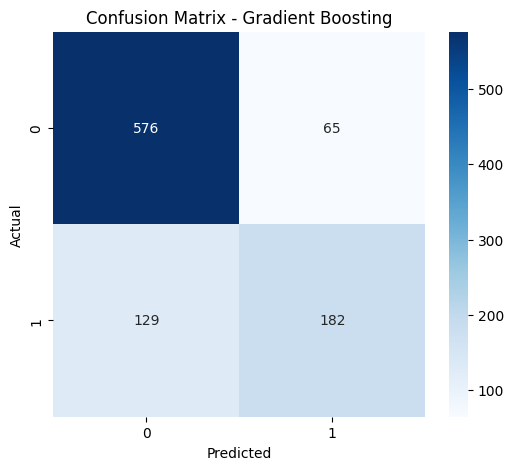

Best Model: Gradient Boosting


In [30]:
#Confusion matrix for the best model
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_val)

cm = confusion_matrix(
    y_val,
    best_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

print("Best Model:", best_model_name)

In [31]:
#Ensemble model
#Soft voting ensemble
from sklearn.ensemble import VotingClassifier

ensemble_model = VotingClassifier(
    estimators=[
        ('lr', logistic_model),
        ('rf', random_forest_model),
        ('et', extra_trees_model),
        ('gb', gradient_boosting_model),
        ('ada', adaboost_model)
    ],
    voting='soft',
    weights=[1, 2, 2, 2, 1],
    n_jobs=-1
)

evaluate_model(
    'Ensemble Model',
    ensemble_model
)


Model: Ensemble Model
Accuracy: 0.7931
Precision: 0.6993
Recall: 0.6431
F1 Score: 0.67
ROC AUC: 0.8364

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       641
           1       0.70      0.64      0.67       311

    accuracy                           0.79       952
   macro avg       0.77      0.75      0.76       952
weighted avg       0.79      0.79      0.79       952



VotingClassifier(estimators=[('lr',
                              Pipeline(steps=[('preprocessor',
                                               ColumnTransformer(transformers=[('num',
                                                                                Pipeline(steps=[('imputer',
                                                                                                 SimpleImputer(strategy='median')),
                                                                                                ('scaler',
                                                                                                 StandardScaler())]),
                                                                                ['covid_concern',
                                                                                 'covid_knowledge',
                                                                                 'behavioral_antiviral_meds',
                                                                                 'behavioral_avoidance',
                                                                                 'behavioral_face_mask',
                                                                                 'behavioral_wash_hands',
                                                                                 'behavioral_large_ga...
                                                                                                ('encoder',
                                                                                                 OneHotEncoder(handle_unknown='ignore',
                                                                                                               sparse_output=False))]),
                                                                                ['age_group',
                                                                                 'education',
                                                                                 'race',
                                                                                 'sex',
                                                                                 'income_poverty',
                                                                                 'marital_status',
                                                                                 'rent_or_own',
                                                                                 'employment_status',
                                                                                 'census_msa',
                                                                                 'employment_sector'])])),
                                              ('classifier',
                                               AdaBoostClassifier(learning_rate=0.5,
                                                                  n_estimators=150,
                                                                  random_state=42))]))],
                 n_jobs=-1, voting='soft', weights=[1, 2, 2, 2, 1])

In [32]:
#Updated model comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

display(results_df)

print("Best performing model:")
print(results_df.iloc[0])

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Ensemble Model,0.793067,0.699301,0.643087,0.670017,0.836409
1,Gradient Boosting,0.796218,0.736842,0.585209,0.652330,0.832988
2,Random Forest,0.793067,0.699301,0.643087,0.670017,0.830420
3,AdaBoost,0.794118,0.757848,0.543408,0.632959,0.829763
4,Extra Trees,0.786765,0.680000,0.655949,0.667758,0.828418
5,Logistic Regression,0.769958,0.624324,0.742765,0.678414,0.828238


Best performing model:
Model        Ensemble Model
Accuracy           0.793067
Precision          0.699301
Recall             0.643087
F1 Score           0.670017
ROC AUC            0.836409
Name: 0, dtype: object


In [33]:
#Generate the five submission CSV files
#Select the best five models
# Rank all models based on validation ROC AUC

ranked_models = results_df['Model'].tolist()

top_5_models = ranked_models[:5]

print("Top 5 Models Selected:")

for rank, model_name in enumerate(top_5_models, 1):
    print(rank, model_name)

Top 5 Models Selected:
1 Ensemble Model
2 Gradient Boosting
3 Random Forest
4 AdaBoost
5 Extra Trees


In [34]:
#Retrain selected models on complete training data
from sklearn.base import clone

final_models = {}

for model_name in top_5_models:

    print("Training:", model_name)

    final_model = clone(
        trained_models[model_name]
    )

    final_model.fit(X, y)

    final_models[model_name] = final_model

print("\nAll five models trained successfully!")

Training: Ensemble Model
Training: Gradient Boosting
Training: Random Forest
Training: AdaBoost
Training: Extra Trees

All five models trained successfully!


In [35]:
#Generate predictions and save CSV files
import os

group_number = 0  # CHANGE THIS TO YOUR GROUP NUMBER

output_folder = '/content/submissions'

os.makedirs(
    output_folder,
    exist_ok=True
)

for rank, model_name in enumerate(top_5_models, 1):

    model = final_models[model_name]

    # Predict vaccine acceptance
    predictions = model.predict(X_test)

    # Create submission dataframe
    submission = pd.DataFrame({
        'respondent_id': test_ids,
        'covid_vaccine': predictions.astype(int)
    })

    # Required filename
    filename = (
        f'challenge_submission_group_'
        f'{group_number}_order_{rank}.csv'
    )

    filepath = os.path.join(
        output_folder,
        filename
    )

    submission.to_csv(
        filepath,
        index=False
    )

    print("Saved:", filename)

print("\nAll five submission files generated!")

Saved: challenge_submission_group_0_order_1.csv
Saved: challenge_submission_group_0_order_2.csv
Saved: challenge_submission_group_0_order_3.csv
Saved: challenge_submission_group_0_order_4.csv
Saved: challenge_submission_group_0_order_5.csv

All five submission files generated!


In [36]:
#Check submission files
for filename in sorted(os.listdir(output_folder)):

    filepath = os.path.join(
        output_folder,
        filename
    )

    df = pd.read_csv(filepath)

    print("\nFile:", filename)

    print("Shape:", df.shape)

    print("Columns:", df.columns.tolist())

    print("Missing Values:", df.isnull().sum().sum())

    print("Target Distribution:")
    print(df['covid_vaccine'].value_counts())

    assert list(df.columns) == [
        'respondent_id',
        'covid_vaccine'
    ]

    assert len(df) == len(test)

    assert df['respondent_id'].equals(test_ids)

print("\nAll submission files passed basic checks!")


File: challenge_submission_group_0_order_1.csv
Shape: (4749, 2)
Columns: ['respondent_id', 'covid_vaccine']
Missing Values: 0
Target Distribution:
covid_vaccine
0    3293
1    1456
Name: count, dtype: int64

File: challenge_submission_group_0_order_2.csv
Shape: (4749, 2)
Columns: ['respondent_id', 'covid_vaccine']
Missing Values: 0
Target Distribution:
covid_vaccine
0    3466
1    1283
Name: count, dtype: int64

File: challenge_submission_group_0_order_3.csv
Shape: (4749, 2)
Columns: ['respondent_id', 'covid_vaccine']
Missing Values: 0
Target Distribution:
covid_vaccine
0    3192
1    1557
Name: count, dtype: int64

File: challenge_submission_group_0_order_4.csv
Shape: (4749, 2)
Columns: ['respondent_id', 'covid_vaccine']
Missing Values: 0
Target Distribution:
covid_vaccine
0    3548
1    1201
Name: count, dtype: int64

File: challenge_submission_group_0_order_5.csv
Shape: (4749, 2)
Columns: ['respondent_id', 'covid_vaccine']
Missing Values: 0
Target Distribution:
covid_vaccine
0    3

In [37]:
#Hospitalisation cost optimisation
#Hospitalisation cost scenario calculator
VACCINE_COST = 1500
HOSPITAL_COST = 41000

# Assumed vaccine effectiveness against hospitalisation
vaccine_effectiveness = 0.70

# Example assumed hospitalisation probability
baseline_probability = 0.10

# Expected cost without vaccination
cost_without_vaccine = (
    baseline_probability * HOSPITAL_COST
)

# Expected cost with vaccination
cost_with_vaccine = (
    VACCINE_COST
    +
    baseline_probability
    * (1 - vaccine_effectiveness)
    * HOSPITAL_COST
)

print("Cost without vaccine:",
      round(cost_without_vaccine, 2))

print("Cost with vaccine:",
      round(cost_with_vaccine, 2))

print("Savings from vaccination:",
      round(cost_without_vaccine - cost_with_vaccine, 2))

# Break-even hospitalisation probability

break_even = (
    VACCINE_COST /
    (vaccine_effectiveness * HOSPITAL_COST)
)

print("\nBreak-even probability:",
      round(break_even * 100, 2), "%")

Cost without vaccine: 4100.0
Cost with vaccine: 2730.0
Savings from vaccination: 1370.0

Break-even probability: 5.23 %
